Cell 1: Setup

In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Show longer text in table cells (default cuts text at 50 characters)
pd.set_option("display.max_colwidth", 150)

df = pd.read_csv("../data/raw/fctr.csv", sep="\t")
print("Shape: ", df.shape)

Shape:  (3238, 7)


In [2]:
df.head(10)

,claim_id,claim,evidence,summary,label,url,date
0,2,Amazon'un Türkiye'de teslim edilmemiş ürünleri uygun fiyata satışa çıkardığı iddiası,Sosyal medyada sık sık yapılan paylaşımlarla Amazon’un sahiplerine ulaşamayan paketleri hediye ettiği veya cüzi miktarlarda sattığı iddia edildi.İ...,"Amazon Türkiye’de teslim edilemeyen paketlerin yeniden satışa çıkarılması gibi bir uygulama yok.ABD’de yürütülen bu uygulamada satışlar, Amazon’da...",yanlış,https://teyit.org/analiz/amazonun-turkiyede-teslim-edilmemis-urunleri-uygun-fiyata-satisa-cikardigi-iddiasi,11/07/2023
1,5,Mickey Mouse’un penisiyle peynir deldiği film Disney’e mi ait?,Walt Disney'in en çok tanınan karakterlerinden olan Mickey Mouse'a ait bir bölümde müstehcen görüntüler olduğu iddia edildi. Videoda Mickey'nin İs...,İddia görüntü dijital içerik üreten kullanıcı tarafından oluşturulmuş.Orijinal bölümde benzeri bir içerik yer almıyor.,yanlış,https://teyit.org/analiz/mickey-mouseun-penisiyle-peynir-deldigi-film-disneye-mi-ait,11/07/2023
2,6,Kurtlar Vadisi'nde Milli Muharip Uçak'ın öngörüldüğü iddiası,"Sosyal medyada bazı kullanıcılar Kurtlar Vadisi dizisinin 2009’da yayınlanan bir bölümünde, Türk Havacılık ve Uzay Sanayii AŞ (TUSAŞ) tarafından M...","Dizide kullanılan görsel Joint Strike Fighter projesi kapsamında üretilen F-35C’ye ait.Kaan isimli savaş uçağının fotoğrafı, dizide kullanılan F-3...",yanlış,https://teyit.org/analiz/kurtlar-vadisinde-milli-muharip-ucakin-gorundugu-iddiasi,11/07/2023
3,7,Basketbol topu şeklindeki binanın gerçek olduğu iddiası,"Sosyal medyada yapılan bir paylaşımda, görüntülerdeki binanın bilgisayar teknolojisi ile tasarlanmamış gerçek bir bina olduğu iddia edildi. Bazı s...","Görüntülerdeki bina “Madison Square Garden Sphere” olarak isimlendirilen bir eğlence merkezi.Binanın 2,3 milyar dolara yapıldığı tahmin ediliyor.B...",doğru,https://teyit.org/analiz/basketbol-topu-seklindeki-binanin-gercek-oldugu-iddiasi,10/07/2023
4,13,Threads'in logosunun Homer Simpson'ın kulaklarından esinlenildiği iddiası,"5 Temmuz 2023’te Instagram, yeni bir mikroblog uygulaması olan Threads’i tanıttı. Threads logo dizaynıyla ilgili henüz resmi bir açıklama yapılmas...","Homer Simpson’ın orijinal çizimlerindeki kulakları, Threads logosuna benzemiyor.Homer’in kulaklarını Threads logosuna benzeterek paylaşılan fotoğr...",yanlış,https://teyit.org/analiz/threadsin-logosunun-homer-simpsonin-kulaklarindan-esinlenildigi-iddiasi,10/07/2023
5,14,ABD’de uçan araba testinin onaylandığı iddiası,Sosyal medyada Amerika Birleşik Devletleri'nde uçan araba testinin onaylandığı iddia edildi. Paylaşımlardan hareket halindeyken havada yükselip be...,"İddiaya konu olan uçan araba Alef Aeronautics şirketinin ürettiği “Model A” aracı.Amerika Federal Havacılık Dairesi, Model A’ya “Uçuşa Elverişlili...",doğru,https://teyit.org/analiz/abdde-alef-aeronauticsin-urettigi-ucan-araba-testinin-onaylandigi-iddiasi,08/07/2023
6,15,İnegöl'deki Göçmen Sağlık Merkezi’nin yer aldığı binada yalnızca göçmenlere hizmet verildiği iddiası,Sosyal medyada yapılan paylaşımlarda Bursa’nın İnegöl ilçesindeki Göçmen Sağlığı Merkezi tabelası bulunan binada yalnızca göçmenlere hizmet verild...,İnegöl’deki 2 No’lu Göçmen Sağlığı Merkezi aynı zamanda Sağlıklı Hayat Merkezi olarak kullanılıyor.Sağlıklı Hayat Merkezleri kapsamında beslenme d...,yanlış,https://teyit.org/analiz/inegoldeki-gocmen-saglik-merkezinin-yer-aldigi-binada-yalnizca-gocmenlere-hizmet-verildigi-iddiasi,07/07/2023
7,18,Threads hesabını silen kullanıcıların Instagram hesabının da silineceği iddiası,"Instagram'ın metin tabanlı konuşma uygulaması olan Threads, Twiter’a alternatif olarak açıldı. 5 Temmuz 2023 gece yarısı kullanıma açılan platform...",Threads hesabını tamamen silmenin tek yolu 6 Temmuz itibariyle Instagramı da kapatmaktan geçiyor.Threads hesabını donduran kullanıcıların bağlı ol...,doğru,https://teyit.org/analiz/threads-hesabini-silen-kullanicilarin-instagram-hesabinin-da-silinecegi-iddiasi,06/07/2023
8,28,Slovenya'da bir başhemşirenin üç fa

Cell 2: Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3238 entries, 0 to 3237
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   claim_id  3238 non-null   int64
 1   claim     3238 non-null   str  
 2   evidence  3238 non-null   str  
 3   summary   3238 non-null   str  
 4   label     3238 non-null   str  
 5   url       3238 non-null   str  
 6   date      3238 non-null   str  
dtypes: int64(1), str(6)
memory usage: 12.6 MB


Cell 3: Missing values

In [4]:
text_cols = ["claim", "evidence", "summary", "label", "url", "date"]

missing = pd.DataFrame({
    "nan": df[text_cols].isna().sum(),
    # Count strings that are empty after removing spaces
    "empty_string": df[text_cols].apply(
        lambda col: (col.fillna("x").astype(str).str.strip() == "").sum()
    ),
})
missing

,nan,empty_string
claim,0,0
evidence,0,0
summary,0,0
label,0,0
url,0,0
date,0,0


Cell 4: Inspect missing summaries

In [5]:
df[df["summary"].isna()][["claim_id", "claim", "url"]].head(10)

,claim_id,claim,url


Cell 5: Duplicates

In [6]:
print("claim_id unique: ", df["claim_id"].is_unique)
print("Fully identicla rows: ", df.duplicated().sum())
print("Duplicate URLs: ", df["url"].duplicated().sum())
print("Duplicate claim texts: ", df["claim"].duplicated().sum())
 

claim_id unique:  True
Fully identicla rows:  0
Duplicate URLs:  0
Duplicate claim texts:  0


Cell 6: Inspect duplicate claims

In [7]:
dup_claims = df[df["claim"].duplicated(keep=False)].sort_values("claim")
dup_claims[["claim_id", "claim", "label", "url", "date"]]

,claim_id,claim,label,url,date


Cell 7: Extract source from URL

In [8]:
df["source"] = df["url"].str.extract(r"https?://(?:www\.)?([^/]+)")[0]
df["source"].value_counts()

source
teyit.org           1971
dogrulukpayi.com     742
dogrula.org          525
Name: count, dtype: int64

Cell 8: Labels by source

In [9]:
# A crosstab generates a cross-tabulation of two categorical columns: the frequency with which each label appears in each source. Setting `margins=True` adds row and column totals.
pd.crosstab(df["label"], df["source"], margins=True)

source,dogrula.org,dogrulukpayi.com,teyit.org,All
label,,,,
doğru,16,45,142,203
karma,0,0,109,109
kismen yanliş,0,72,0,72
sonuçlandırılamadı,0,0,37,37
yanlış,472,625,1683,2780
yarı doğru,17,0,0,17
çoğunlukla doğru,6,0,0,6
çoğunlukla yanlış,14,0,0,14
All,525,742,1971,3238


Cell 9: Inspect label strings exactly

In [10]:
for label in df["label"].unique():
    # repr() displays a piece of text exactly as it is.
    print(repr(label))

'yanlış'
'doğru'
'karma'
'sonuçlandırılamadı'
'kismen yanliş'
'çoğunlukla doğru'
'çoğunlukla yanlış'
'yarı doğru'


Cell 9: Parse dates

In [11]:
# Tell pandas the exact format: day/month/year
df["date_parsed"] = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce")

print("Failed to parse: ", df["date_parsed"].isna().sum())
print("Earliest: ", df["date_parsed"].min())
print("Latest: ", df["date_parsed"].max())

Failed to parse:  0
Earliest:  2016-07-23 00:00:00
Latest:  2023-07-12 00:00:00


In [12]:
df[df["date_parsed"].isna()][["claim_id", "date", "url"]]

,claim_id,date,url


Cell 10: Claims per year

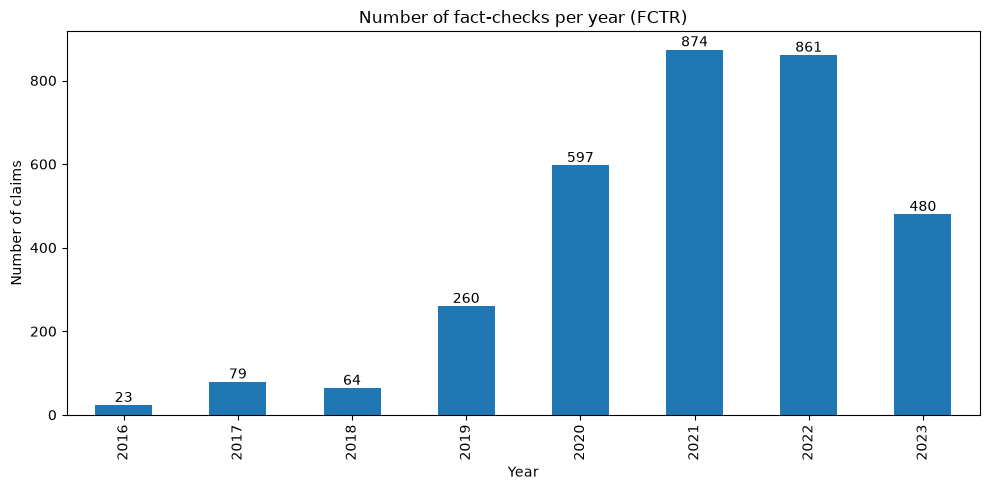

In [17]:
year_counts = df["date_parsed"].dt.year.value_counts().sort_index()

ax = year_counts.plot(kind="bar", figsize=(10,5))

for container in ax.containers:
    ax.bar_label(container)

ax.set_title("Number of fact-checks per year (FCTR)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of claims")
plt.tight_layout()
plt.show()

Cell 11: Text length statistics

In [18]:
for col in ["claim", "evidence", "summary"]:
    df[f"{col}_len"] = df[col].fillna("").str.len()

df[["claim_len", "evidence_len", "summary_len"]].describe().round(0)

,claim_len,evidence_len,summary_len
count,3238.0,3238.0,3238.0
mean,101.0,3057.0,347.0
std,61.0,2020.0,199.0
min,22.0,169.0,40.0
25%,63.0,1763.0,201.0
50%,78.0,2550.0,300.0
75%,106.0,3715.0,444.0
max,514.0,27571.0,2064.0


Cell 12: Length distributions

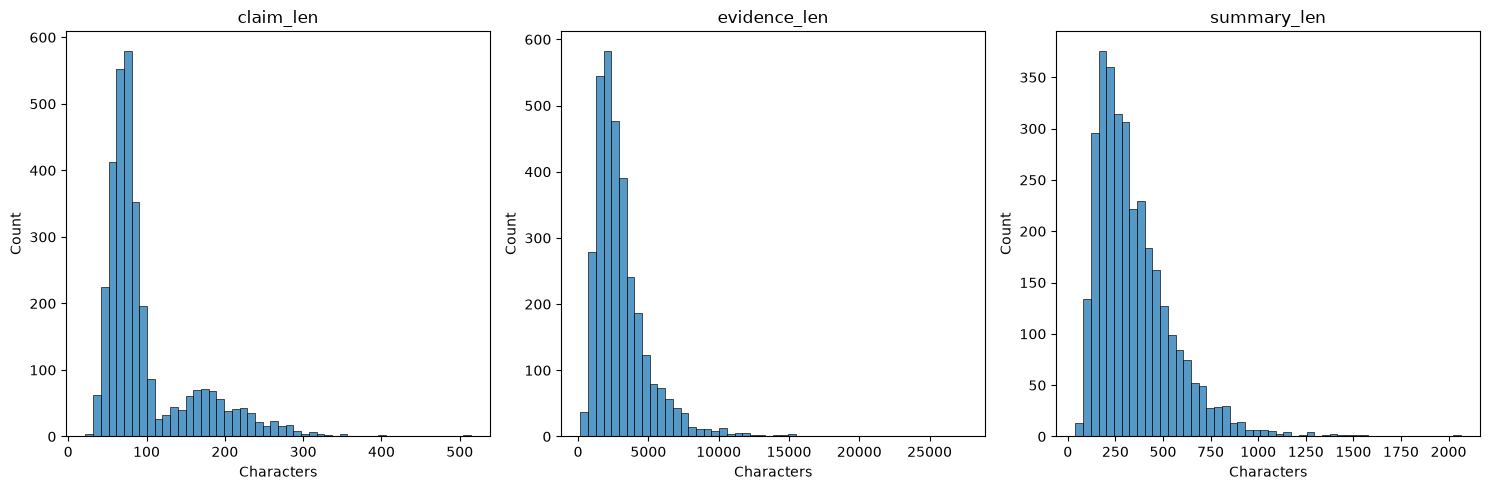

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ax, col in zip(axes, ["claim_len", "evidence_len", "summary_len"]):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Characters")
plt.tight_layout()
plt.show()

Cell 13: Shortest evidence texts

In [23]:
df.nsmallest(10, "evidence_len")[["claim_id", "claim", "evidence", "evidence_len"]]

,claim_id,claim,evidence,evidence_len
2904,6253,Muhalefeti eleştiren Twitter paylaşımının Tamer Karadağlı’ya ait olduğu iddiası,"Paylaşımın yayılmasının ardından aktör Tamer Karadağlı, Instagram hesabında paylaştığı hikayede, sözü geçen Twitter hesabı ve paylaşımın kendine a...",169
3147,6680,The Simpsons sahnesi aşı karşıtı mesaj vermiyor,"Görüntüler orijinal değil, yazı eklenmişGörseldeki görüntüler 16. sezon 12. bölümde yer alıyor. Fakat görüntülerdeki orijinal yazılar silinerek ba...",217
3220,6769,"Söyleyen yurtdışındaki turist acentesi değil, Fatih’teki turist rehberi","Reuters’ın HaberiHaberde “Türkiye’ye gitmek için en iyi zaman çünkü Türkler dışarı çıkamıyor” ifadesi yer alıyor. Fakat, habere göre bu ifadenin s...",274
2996,6449,İBB bilboard’lara ‘Cumhurbaşkanı onaylamadı’ afişi asmadı,Sözde Bilboardlar Aslında Stok Fotoğraflar ve Üzerinde Düzenleme YapılmışGörseli Google Images üzerinde tersine arama yöntemi kullanarak tarattığı...,337
3143,6672,Köpekle adamın sarılma anı Türkiye’deki yangında kaydedilmedi,"Fotoğrafın eski tarihli olduğu ortaya çıktı.Görseli, arama motorlarında arattığımızda görselin 2015’e kadar uzanan tarihlerde, çok sayıda farklı p...",428
3023,6488,Alman çiftçilerin protestosunun pandemi ile ilgisi yok,"Video 2019’da çekilmişVideonun ilk karesini ekran görüntüsü alıp, arama motorlarının görsel arama özelliğini kullanarak taradığımızda ilgili haber...",434
2821,6036,“Eldivenler sedyede kalmış” tweet’ini Altay futbol takımının kalecisi Ozan Evrim Özenç’in paylaştığı iddiası,Twitter’da @ozanevrimozenc kullanıcı isimli Twitter hesabının paylaşımının ardından söz konusu hesabı inceledik. Özenç’in Instagram hesabından kon...,437
2899,6243,RTÜK’ün Türkiye’nin risk primi (CDS) konulu haberleri yasakladığı iddiası,"Paylaşımı yapan hesap, söz konusu gönderinin altında “Tencerenin dibi tutmadan, en eski özdeyişimizi not edelim: ironiden anlamayan nesle aşina de...",443
2874,6189,BİM’e 12 Ağustos’ta psikolog geleceği iddiası,"BİM’in web sitesinde yer alan 12 Ağustos Cuma tarihli ürün kataloğu incelendiğinde, psikolog seansı olduğu öne sürülen kısmın dijital müdahaleyle ...",456
2008,4089,Bir Twitter hesabı tarafından 14 Mayıs 2023 tarihinde yapılan paylaşımda Edirne’de bir gencin oy kullanırken elini kırdığı iddia edildi.,"Görsel, arama motorunda tersine aratıldığında Donanım Haber Forum isimli internet sitesinde Sağ Elim Alçıda (SS’li) başlığının altında iddiada yer...",512


Cell 14: Glued sentences

In [24]:
# A sentence-ending mark directly followed by an uppercase letter: "edildi.İddialara"
glued_pattern =r"[.!?][A-ZÇĞİÖŞÜ]"

df["glued_count"] = df["evidence"].fillna("").str.count(glued_pattern)

affectted = (df["glued_count"] > 0).sum()
print(f"Records with glued sentences: {affectted} / {len(df)} ({affectted / len(df):.0%})")
print("Total glued spots: ", df["glued_count"].sum())

Records with glued sentences: 2442 / 3238 (75%)
Total glued spots:  13710


Cell 15: Possibly truncated texts

In [25]:
last_char = df["evidence"].fillna("").str.strip().str[-1]
ends_properly = last_char.isin(list('.!?"”)'))

truncated = df[~ends_properly]
print(f"Evidence not ending with punctuation: {len(truncated)} / {len(df)}")
truncated[["claim_id", "evidence_len"]].assign(
    ending=truncated["evidence"].str.strip().str[-80:]
).head(10)

Evidence not ending with punctuation: 113 / 3238


,claim_id,evidence_len,ending
14,68,4771,"rı için heyecan verici. Monash Üniversitesi’nin ürettiği embriyo modelleri, 2021"
144,359,3370,"ilir: Bir buçuk dil, bir buçuk insan: Yanlış çeviri yanlış bilgiye kapı aralıyor"
168,431,8659,r. İlginizi çekebilir: Deprem tahmincileri korkulardan beslenerek fayda sağlıyor
244,577,1462,ansıyan bedeller değil.1 Ocak 2023’ten itibaren uygulanan güncel ücretler şöyle:
295,662,4316,"n adın seviyorum olsunseviyorum olsunseni seviyorum,seni seviyorumSebahattin Abi"
326,744,5764,adımlardan.İlginizi çekebilir: İklim krizinde doğru bilgiye yer açmanın yolları
338,764,2239,Yanlış bilgi sorununun çözümü hapis cezası değil eleştirel dijital okuryazarlık
377,836,3683,"ebilir: Komplo teorileriyle mücadele: Saptamak, çürütmek ve inananlarla konuşmak"
451,972,3091,protesto etmişti.Almanya Milli Futbol Takımı’nın İzlanda maçı öncesi protestosu
453,976,1903,"afı da farklı kişilere ait.Bahar Topçu, sokak röportajındaki kişi ve Sevgi Kılıç"


Cell 16: Multimodal claims

In [26]:
media_pattern = r"video|fotoğraf|görsel|görüntü|resim"
df["is_multimodal"] = df["claim"].str.contains(media_pattern, case=False, regex=True)

print(f"Claims mentioning media: {df['is_multimodal'].sum()} / {len(df)} "
      f"({df['is_multimodal'].mean():.0%})")

Claims mentioning media: 6 / 3238 (0%)


## Findings

- **Size:** 3,238 records, 7 columns. Matches the paper.
- **Missing values:** 0 records.
- **Duplicates:** 0
- **Sources:** Teyit 1,971, Doğruluk Payı 742, Doğrula 525 (paper: 1,971 / 742 / 525).
- **Labels:** 8 distinct labels; intermediate labels belong to a single publisher each.
  Spelling inconsistency: `kismen yanliş` should be `kısmen yanlış`.
- **Class imbalance:** 85.9% "yanlış", 6.3% "doğru".
- **Dates:** Stored as text in DD/MM/YYYY format. Range 2016-07-23 to 2023-07-12 (matches paper).
- **Text quality:** Glued sentences in 75% of records; 113 evidence texts may be truncated.
- **Multimodal claims:** 0% (only 6) of claims mention a video or image.